
# Interactive Sales Dashboard 📊

## Week 6 — Data Visualization Mastery with Seaborn

### Project Overview
This project analyzes sales data using Pandas, creates statistical visualizations with Seaborn, and builds an interactive dashboard using Plotly.

### Objectives
- Analyze sales data using Pandas.
- Create bar charts, box plots, line charts, and correlation heatmaps.
- Explore product and regional sales performance.
- Build interactive visualizations using Plotly.
- Present key performance indicators in a dashboard.


In [2]:

# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from pathlib import Path

# Set Seaborn theme
sns.set_theme(style="whitegrid", palette="deep")

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Load the sales dataset

data_path = Path("data") / "sales_data.csv"

df = pd.read_csv(data_path)

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Display first five rows
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (100, 7)


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [4]:

# ----------------------------------------
# Cell 4: Data Exploration
# ----------------------------------------

print("DATASET INFORMATION")
print("=" * 40)

# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check column data types
print("\nData Types:")
print(df.dtypes)

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())


DATASET INFORMATION
Rows: 100
Columns: 7

Missing Values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64

Duplicate Records: 0

Data Types:
Date           datetime64[us]
Product                   str
Quantity                int64
Price                   int64
Customer_ID               str
Region                    str
Total_Sales             int64
dtype: object

Statistical Summary:


,Date,Quantity,Price,Total_Sales
count,100,100.000000,100.000000,100.000000
mean,2024-02-19 12:00:00,4.780000,25808.510000,123650.480000
min,2024-01-01 00:00:00,1.000000,1308.000000,6540.000000
25%,2024-01-25 18:00:00,2.750000,14965.250000,39517.500000
50%,2024-02-19 12:00:00,5.000000,24192.000000,97955.500000
75%,2024-03-15 06:00:00,7.000000,38682.250000,175792.500000
max,2024-04-09 00:00:00,9.000000,49930.000000,373932.000000
std,NaN,2.588163,13917.630242,100161.085275


In [5]:

# ----------------------------------------
# Cell 5: Sales KPI Analysis
# ----------------------------------------

# Calculate key performance indicators
total_revenue = df["Total_Sales"].sum()
total_units = df["Quantity"].sum()
average_sale = df["Total_Sales"].mean()
total_products = df["Product"].nunique()
total_regions = df["Region"].nunique()

# Display KPI results
print("SALES PERFORMANCE SUMMARY")
print("=" * 40)

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Sale Value: ${average_sale:,.2f}")
print(f"Unique Products: {total_products}")
print(f"Regions Covered: {total_regions}")


SALES PERFORMANCE SUMMARY
Total Revenue: $12,365,048.00
Total Units Sold: 478
Average Sale Value: $123,650.48
Unique Products: 5
Regions Covered: 4


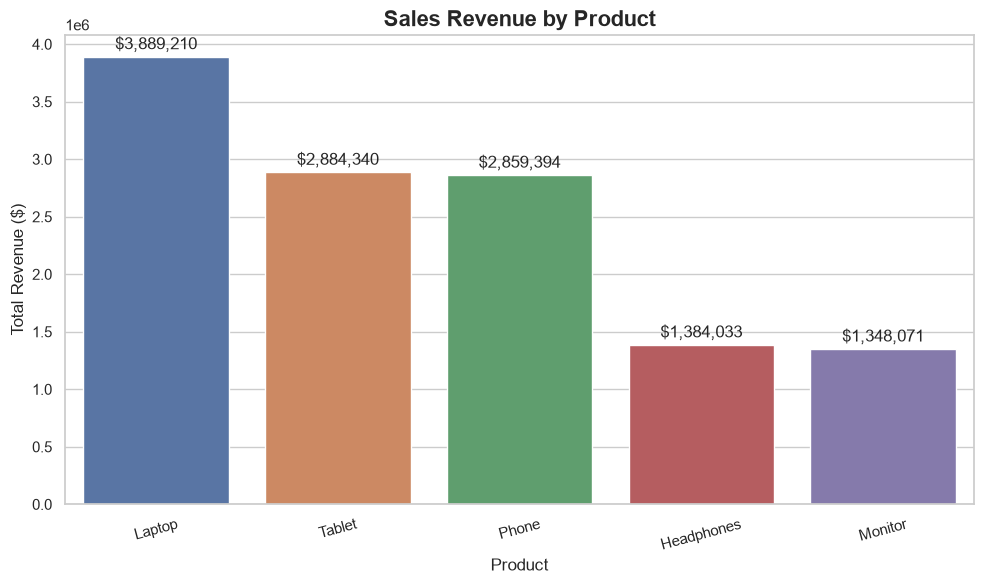

Revenue by Product:


,Product,Total_Sales
1,Laptop,3889210
4,Tablet,2884340
3,Phone,2859394
0,Headphones,1384033
2,Monitor,1348071


In [6]:

# ----------------------------------------
# Cell 6: Sales Revenue by Product
# ----------------------------------------

# Calculate revenue for each product
product_sales = (
    df.groupby("Product", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

# Create the bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=product_sales,
    x="Product",
    y="Total_Sales",
    hue="Product",
    legend=False
)

# Customize chart
plt.title("Sales Revenue by Product", fontsize=16, fontweight="bold")
plt.xlabel("Product")
plt.ylabel("Total Revenue ($)")

# Display revenue labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"${value:,.0f}" for value in container.datavalues],
        padding=3
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Display product revenue table
print("Revenue by Product:")
display(product_sales)


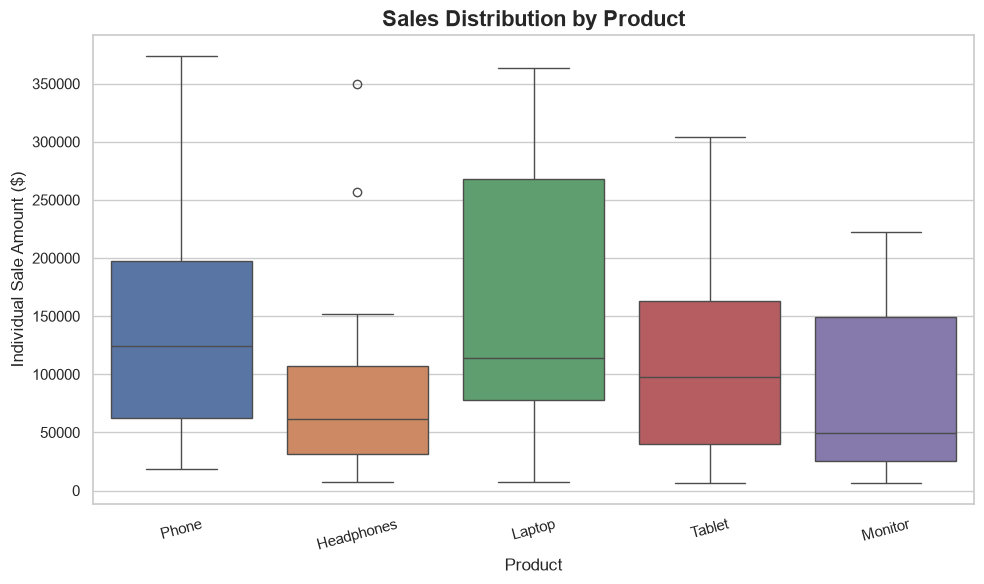

Sales distribution box plot created successfully!


In [7]:

# ----------------------------------------
# Cell 7: Sales Distribution by Product
# ----------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df,
    x="Product",
    y="Total_Sales",
    hue="Product",
    legend=False
)

# Customize the chart
plt.title(
    "Sales Distribution by Product",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product")
plt.ylabel("Individual Sale Amount ($)")

plt.xticks(rotation=15)
plt.tight_layout()

# Display the chart
plt.show()

print("Sales distribution box plot created successfully!")


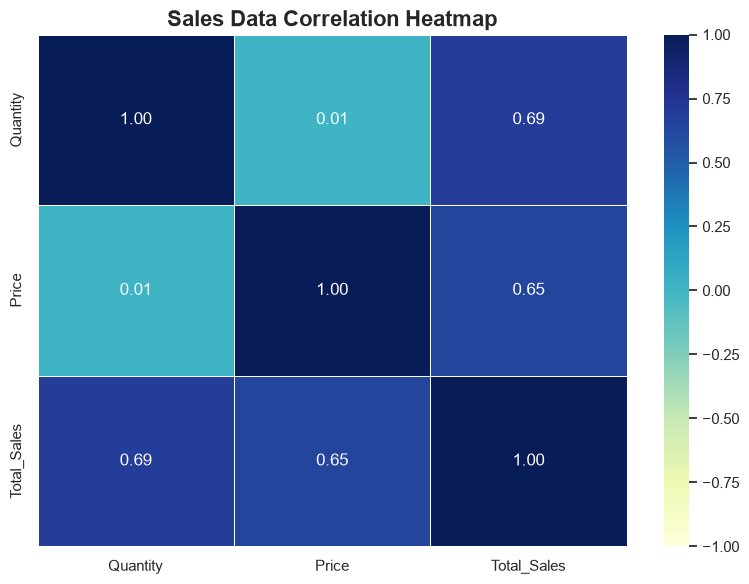

Correlation Matrix:


,Quantity,Price,Total_Sales
Quantity,1.00,0.01,0.69
Price,0.01,1.00,0.65
Total_Sales,0.69,0.65,1.00


In [8]:

# ----------------------------------------
# Cell 8: Correlation Heatmap
# ----------------------------------------

# Select numerical columns
numeric_columns = ["Quantity", "Price", "Total_Sales"]

# Calculate correlation matrix
correlation_matrix = df[numeric_columns].corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

# Customize chart
plt.title(
    "Sales Data Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Display correlation values
print("Correlation Matrix:")
display(correlation_matrix.round(2))


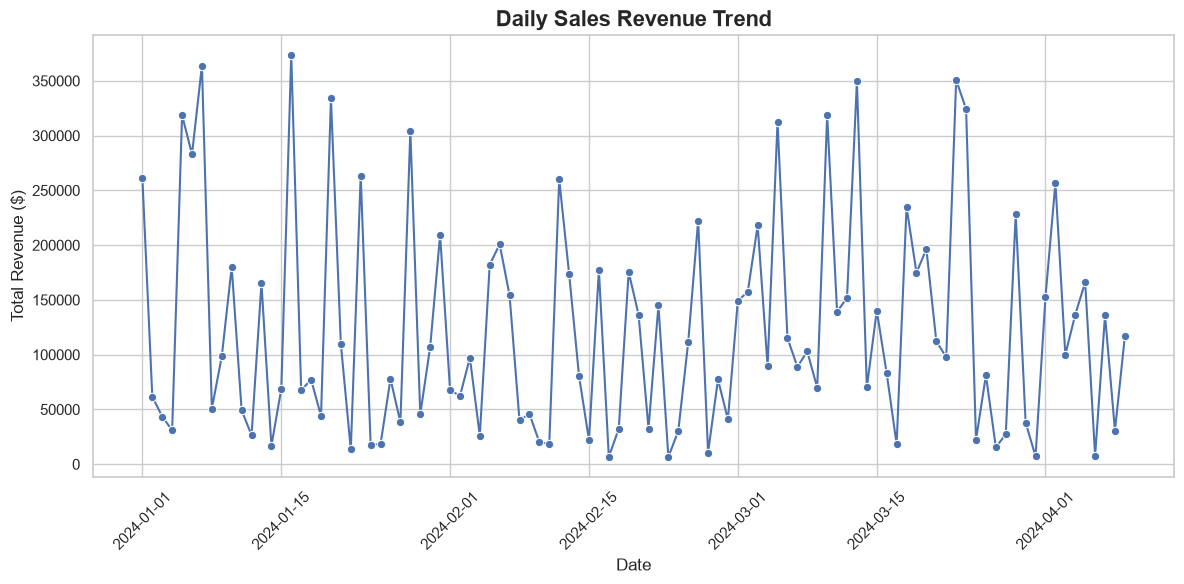

Daily Sales Summary:


,Date,Total_Sales
0,2024-01-01,261100
1,2024-01-02,61624
2,2024-01-03,43492
3,2024-01-04,30895
4,2024-01-05,318680


In [9]:

# ----------------------------------------
# Cell 9: Daily Sales Trend
# ----------------------------------------

# Calculate daily revenue
daily_sales = (
    df.groupby("Date", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Date")
)

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Total_Sales",
    marker="o"
)

# Customize chart
plt.title(
    "Daily Sales Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Display first five daily sales records
print("Daily Sales Summary:")
display(daily_sales.head())


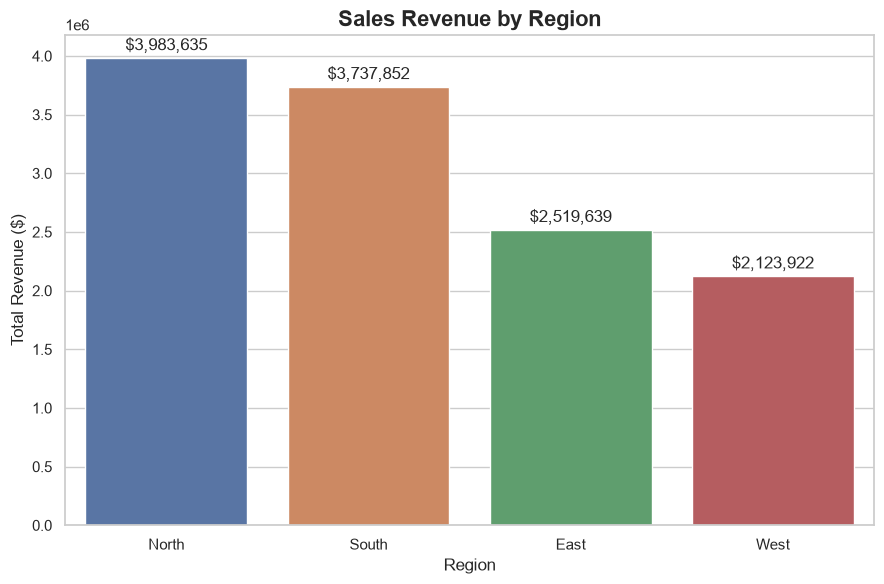

Revenue by Region:


,Region,Total_Sales
1,North,3983635
2,South,3737852
0,East,2519639
3,West,2123922


In [10]:

# ----------------------------------------
# Cell 10: Sales Revenue by Region
# ----------------------------------------

# Calculate total revenue by region
region_sales = (
    df.groupby("Region", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

# Create bar chart
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False
)

# Customize chart
plt.title(
    "Sales Revenue by Region",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Total Revenue ($)")

# Add revenue labels above bars
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"${value:,.0f}" for value in container.datavalues],
        padding=3
    )

plt.tight_layout()
plt.show()

# Display regional revenue
print("Revenue by Region:")
display(region_sales)


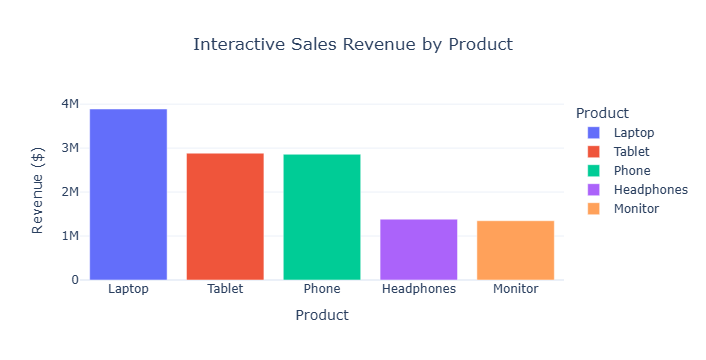

Interactive Plotly chart created successfully!


In [11]:

# ----------------------------------------
# Cell 11: Interactive Sales by Product
# ----------------------------------------

# Create interactive bar chart
interactive_chart = px.bar(
    product_sales,
    x="Product",
    y="Total_Sales",
    title="Interactive Sales Revenue by Product",
    color="Product",
    labels={
        "Product": "Product",
        "Total_Sales": "Revenue ($)"
    },
    hover_data={"Total_Sales": ":,.2f"}
)

# Customize chart appearance
interactive_chart.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_title="Product",
    yaxis_title="Revenue ($)"
)

# Display interactive chart in notebook
interactive_chart.show()

print("Interactive Plotly chart created successfully!")


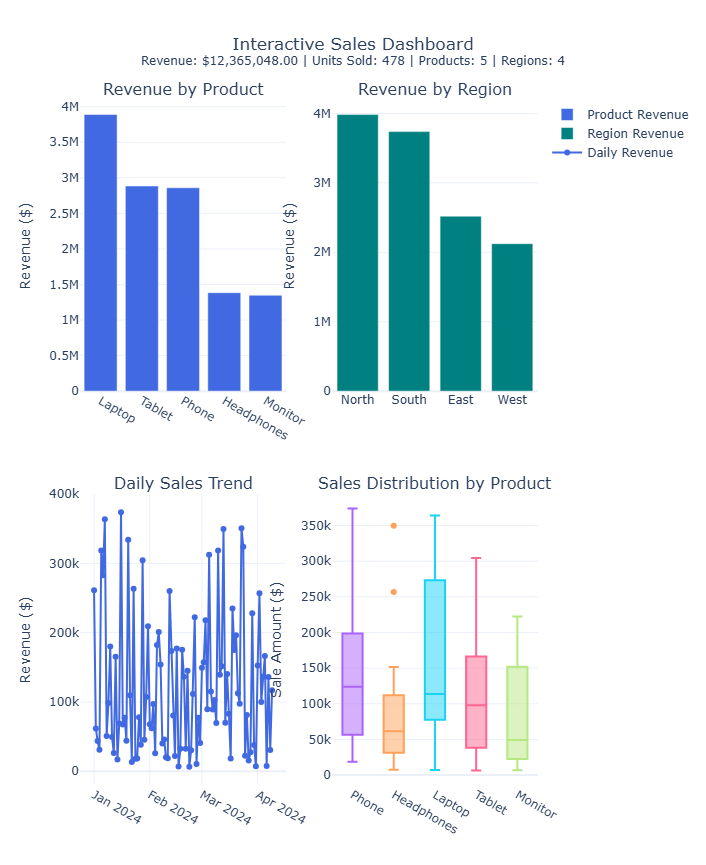

Interactive Sales Dashboard created successfully!


In [12]:

# ----------------------------------------
# Cell 12: Complete Interactive Dashboard
# ----------------------------------------

# Create dashboard layout
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Revenue by Product",
        "Revenue by Region",
        "Daily Sales Trend",
        "Sales Distribution by Product"
    ),
    specs=[
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "scatter"}, {"type": "box"}]
    ],
    vertical_spacing=0.15
)

# Chart 1: Revenue by Product
fig.add_trace(
    go.Bar(
        x=product_sales["Product"],
        y=product_sales["Total_Sales"],
        name="Product Revenue",
        marker_color="royalblue",
        hovertemplate="%{x}<br>Revenue: $%{y:,.2f}<extra></extra>"
    ),
    row=1, col=1
)

# Chart 2: Revenue by Region
fig.add_trace(
    go.Bar(
        x=region_sales["Region"],
        y=region_sales["Total_Sales"],
        name="Region Revenue",
        marker_color="teal",
        hovertemplate="%{x}<br>Revenue: $%{y:,.2f}<extra></extra>"
    ),
    row=1, col=2
)

# Chart 3: Daily Sales Trend
fig.add_trace(
    go.Scatter(
        x=daily_sales["Date"],
        y=daily_sales["Total_Sales"],
        mode="lines+markers",
        name="Daily Revenue",
        line=dict(color="royalblue"),
        hovertemplate="%{x|%Y-%m-%d}<br>Revenue: $%{y:,.2f}<extra></extra>"
    ),
    row=2, col=1
)

# Chart 4: Sales Distribution
for product in df["Product"].unique():
    product_data = df[df["Product"] == product]

    fig.add_trace(
        go.Box(
            x=product_data["Product"],
            y=product_data["Total_Sales"],
            name=product,
            boxpoints="outliers",
            showlegend=False
        ),
        row=2, col=2
    )

# Customize dashboard
fig.update_layout(
    title={
        "text": (
            "Interactive Sales Dashboard"
            "<br><sup>"
            f"Revenue: ${total_revenue:,.2f} | "
            f"Units Sold: {total_units:,} | "
            f"Products: {total_products} | "
            f"Regions: {total_regions}"
            "</sup>"
        ),
        "x": 0.5
    },
    template="plotly_white",
    height=850,
    width=1300,
    hovermode="closest",
    barmode="group"
)

# Add axis labels
fig.update_yaxes(title_text="Revenue ($)", row=1, col=1)
fig.update_yaxes(title_text="Revenue ($)", row=1, col=2)
fig.update_yaxes(title_text="Revenue ($)", row=2, col=1)
fig.update_yaxes(title_text="Sale Amount ($)", row=2, col=2)

# Display dashboard
fig.show()

print("Interactive Sales Dashboard created successfully!")
